# French Bank Portfolio: Diversification and Market Risk Analysis

## Overview
This project compares the historical price performance and market-risk profile of an equal-weighted portfolio of three listed French banks with the CAC 40 benchmark.

## Research Question
Does an equal-weighted portfolio of Société Générale, BNP Paribas, and Crédit Agricole improve risk-adjusted price performance relative to its individual constituents and the CAC 40?

## Scope and Assumptions
- Daily closing prices are used; this is a price-return analysis, not a total-return analysis.
- The portfolio allocates one-third to each bank and is rebalanced daily.
- The analysis is historical and educational only; it is not investment advice.

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
FIGURES_DIR = PROJECT_DIR / "figures"
DATA_DIR = PROJECT_DIR / "data" / "processed"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project folder: {PROJECT_DIR.resolve()}")
print(f"Figures folder: {FIGURES_DIR.resolve()}")
print(f"Data folder: {DATA_DIR.resolve()}")

Project folder: /Users/faraz/french-bank-portfolio-risk
Figures folder: /Users/faraz/french-bank-portfolio-risk/figures
Data folder: /Users/faraz/french-bank-portfolio-risk/data/processed


In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
BANK_TICKERS = {
    "Société Générale": "GLE.PA",
    "BNP Paribas": "BNP.PA",
    "Crédit Agricole": "ACA.PA",
}

BENCHMARK_NAME = "CAC 40"
BENCHMARK_TICKER = "^FCHI"

START_DATE = "2021-09-23"
REQUESTED_END_DATE_EXCLUSIVE = "2026-09-23"

TRADING_DAYS = 252
RISK_FREE_RATE = 0.0

print("Analysis configuration is ready.")
print("Banks:", list(BANK_TICKERS.keys()))
print("Benchmark:", BENCHMARK_NAME)

Analysis configuration is ready.
Banks: ['Société Générale', 'BNP Paribas', 'Crédit Agricole']
Benchmark: CAC 40


## Data Collection and Quality Checks

In [5]:
TICKERS = list(BANK_TICKERS.values()) + [BENCHMARK_TICKER]

raw_download = yf.download(
    TICKERS,
    start=START_DATE,
    end=REQUESTED_END_DATE_EXCLUSIVE,
    auto_adjust=False,
    progress=False
)

print("Raw data downloaded.")

Raw data downloaded.


In [6]:
ticker_to_name = {
    "GLE.PA": "Société Générale",
    "BNP.PA": "BNP Paribas",
    "ACA.PA": "Crédit Agricole",
    "^FCHI": "CAC 40",
}

close_prices = raw_download["Close"].copy()
close_prices = close_prices.rename(columns=ticker_to_name)

asset_names = list(BANK_TICKERS.keys()) + [BENCHMARK_NAME]

# Keep only dates available for all four series
prices = close_prices[asset_names].dropna().copy()

In [7]:
print(f"Number of observations: {len(prices):,}")
print(f"Actual date range: {prices.index.min().date()} to {prices.index.max().date()}")

print("\nMissing values per column:")
print(prices.isna().sum())

prices.head()

Number of observations: 1,280
Actual date range: 2021-09-23 to 2026-09-22

Missing values per column:
Ticker
Société Générale    0
BNP Paribas         0
Crédit Agricole     0
CAC 40              0
dtype: int64


Ticker,Société Générale,BNP Paribas,Crédit Agricole,CAC 40
Date,,,,
2021-09-23,26.045000,54.360001,11.872,6701.979980
2021-09-24,26.334999,54.799999,11.900,6638.459961
2021-09-27,27.170000,56.500000,12.318,6650.910156
2021-09-28,26.535000,54.840000,12.040,6506.500000
2021-09-29,27.115000,55.259998,12.046,6560.799805


In [8]:
# Calculate daily percentage returns
daily_returns = prices.pct_change(fill_method=None).dropna()

print(f"Number of daily-return observations: {len(daily_returns):,}")
print(f"Daily-return range: {daily_returns.index.min().date()} to {daily_returns.index.max().date()}")

daily_returns.head()

Number of daily-return observations: 1,279
Daily-return range: 2021-09-24 to 2026-09-22


Ticker,Société Générale,BNP Paribas,Crédit Agricole,CAC 40
Date,,,,
2021-09-24,0.011135,0.008094,0.002358,-0.009478
2021-09-27,0.031707,0.031022,0.035126,0.001875
2021-09-28,-0.023371,-0.029381,-0.022569,-0.021713
2021-09-29,0.021858,0.007659,0.000498,0.008345
2021-09-30,0.002950,0.003257,-0.008301,-0.006217


## Equal-Weighted Bank Portfolio

In [9]:
# Build an equal-weighted portfolio, rebalanced daily
bank_names = list(BANK_TICKERS.keys())

portfolio_weights = pd.Series(
    1 / len(bank_names),
    index=bank_names,
    name="Weight"
)

portfolio_returns = (
    daily_returns[bank_names]
    .mul(portfolio_weights, axis=1)
    .sum(axis=1)
    .rename("Equal-Weighted Bank Portfolio")
)

assert np.isclose(portfolio_weights.sum(), 1.0)

print("Portfolio weights:")
print(portfolio_weights)

portfolio_returns.head()

Portfolio weights:
Société Générale    0.333333
BNP Paribas         0.333333
Crédit Agricole     0.333333
Name: Weight, dtype: float64


Date
2021-09-24    0.007196
2021-09-27    0.032618
2021-09-28   -0.025107
2021-09-29    0.010005
2021-09-30   -0.000698
Name: Equal-Weighted Bank Portfolio, dtype: float64

## Indexed Performance

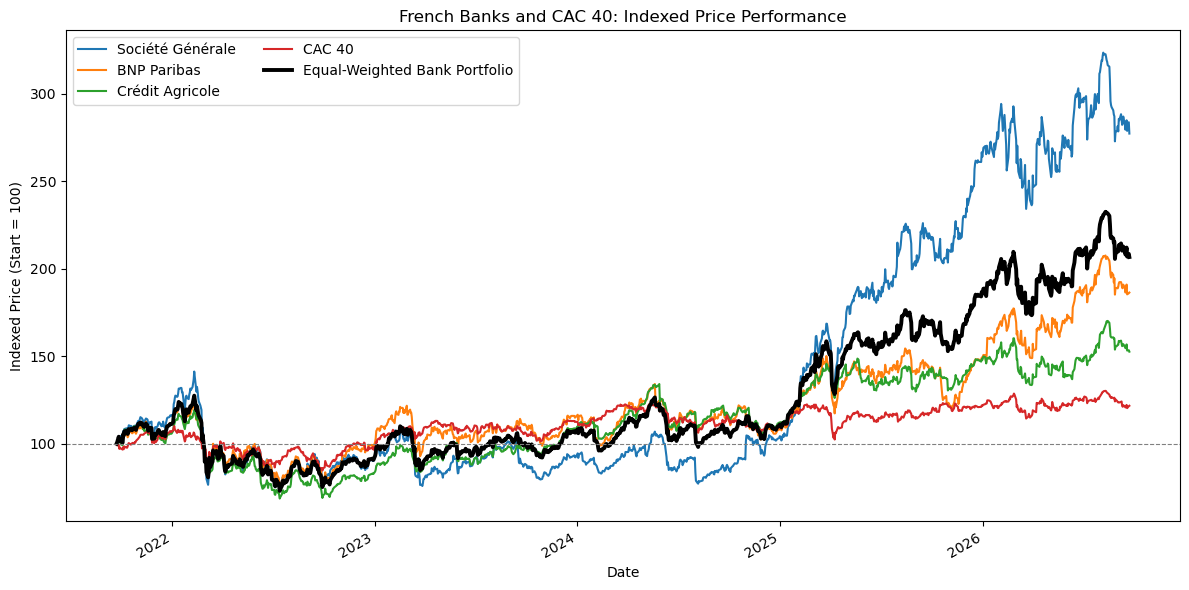

Saved: /Users/faraz/french-bank-portfolio-risk/figures/indexed_performance.png


In [10]:
# Rebase each individual asset to 100 on the first trading day
individual_indexed = prices.div(prices.iloc[0]).mul(100)

# Rebase the daily-rebalanced portfolio to 100 on the first trading day
portfolio_indexed = (
    (1 + portfolio_returns)
    .cumprod()
    .mul(100)
    .rename("Equal-Weighted Bank Portfolio")
)

portfolio_start = pd.Series(
    [100.0],
    index=[prices.index[0]],
    name="Equal-Weighted Bank Portfolio"
)

portfolio_indexed = pd.concat([portfolio_start, portfolio_indexed])

# Combine all series for comparison
indexed_performance = pd.concat(
    [individual_indexed, portfolio_indexed],
    axis=1
)

ax = individual_indexed.plot(figsize=(12, 6), linewidth=1.5)
portfolio_indexed.plot(
    ax=ax,
    color="black",
    linewidth=2.8,
    label="Equal-Weighted Bank Portfolio"
)

ax.axhline(100, color="gray", linewidth=0.8, linestyle="--")
ax.set_title("French Banks and CAC 40: Indexed Price Performance")
ax.set_xlabel("Date")
ax.set_ylabel("Indexed Price (Start = 100)")
ax.legend(title="", ncol=2)

figure_path = FIGURES_DIR / "indexed_performance.png"

plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {figure_path}")

## Correlation Analysis

In [11]:
# Correlation of daily returns across the three banks and the CAC 40
correlation_matrix = daily_returns[asset_names].corr()

correlation_matrix.round(2)

Ticker,Société Générale,BNP Paribas,Crédit Agricole,CAC 40
Ticker,,,,
Société Générale,1.00,0.78,0.75,0.66
BNP Paribas,0.78,1.00,0.77,0.72
Crédit Agricole,0.75,0.77,1.00,0.65
CAC 40,0.66,0.72,0.65,1.00


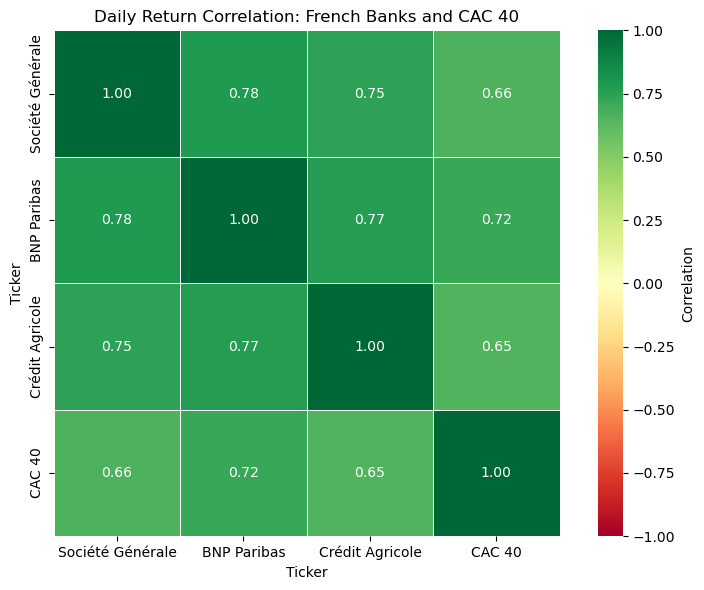

Saved: /Users/faraz/french-bank-portfolio-risk/figures/correlation_matrix.png


In [12]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation"}
)

plt.title("Daily Return Correlation: French Banks and CAC 40")

figure_path = FIGURES_DIR / "correlation_matrix.png"

plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {figure_path}")

## Performance and Risk Summary

In [13]:
# Combine individual assets, portfolio, and benchmark returns
analysis_names = (
    bank_names
    + ["Equal-Weighted Bank Portfolio"]
    + [BENCHMARK_NAME]
)

analysis_returns = pd.concat(
    [daily_returns, portfolio_returns],
    axis=1
)[analysis_names].copy()

analysis_start_date = prices.index.min()
analysis_end_date = prices.index.max()

analysis_years = (
    (analysis_end_date - analysis_start_date).days / 365.25
)

print(f"Analysis period: {analysis_start_date.date()} to {analysis_end_date.date()}")
print(f"Length of period: {analysis_years:.2f} years")

Analysis period: 2021-09-23 to 2026-09-22
Length of period: 5.00 years


In [14]:
# Build cumulative wealth series, starting at 1 on the first trading day
starting_value = pd.DataFrame(
    [np.ones(len(analysis_returns.columns))],
    index=[analysis_start_date],
    columns=analysis_returns.columns
)

wealth_index = pd.concat([
    starting_value,
    (1 + analysis_returns).cumprod()
])

drawdown = wealth_index.div(wealth_index.cummax()).sub(1)

# Calculate key performance and risk metrics
total_price_return = wealth_index.iloc[-1].sub(1)
cagr = wealth_index.iloc[-1].pow(1 / analysis_years).sub(1)

annualized_volatility = (
    analysis_returns.std() * np.sqrt(TRADING_DAYS)
)

annualized_return = analysis_returns.mean() * TRADING_DAYS

sharpe_ratio = (
    (annualized_return - RISK_FREE_RATE)
    / annualized_volatility
)

maximum_drawdown = drawdown.min()

summary = pd.DataFrame({
    "Total Price Return (%)": total_price_return * 100,
    "CAGR (%)": cagr * 100,
    "Annualized Volatility (%)": annualized_volatility * 100,
    "Sharpe Ratio (rf = 0%)": sharpe_ratio,
    "Maximum Drawdown (%)": maximum_drawdown * 100,
})

summary.round(2)

,Total Price Return (%),CAGR (%),Annualized Volatility (%),Sharpe Ratio (rf = 0%),Maximum Drawdown (%)
Société Générale,177.17,22.63,34.43,0.76,-47.86
BNP Paribas,86.35,13.27,28.42,0.57,-38.61
Crédit Agricole,52.59,8.82,24.18,0.47,-42.40
Equal-Weighted Bank Portfolio,106.64,15.63,26.70,0.67,-42.69
CAC 40,21.68,4.01,16.32,0.32,-23.04


## Market Sensitivity: Beta

In [15]:
# Calculate beta relative to the CAC 40
benchmark_returns = analysis_returns[BENCHMARK_NAME]

beta = analysis_returns.apply(
    lambda series: series.cov(benchmark_returns) / benchmark_returns.var()
)

summary["Beta vs CAC 40"] = beta

summary.round(2)

,Total Price Return (%),CAGR (%),Annualized Volatility (%),Sharpe Ratio (rf = 0%),Maximum Drawdown (%),Beta vs CAC 40
Société Générale,177.17,22.63,34.43,0.76,-47.86,1.38
BNP Paribas,86.35,13.27,28.42,0.57,-38.61,1.25
Crédit Agricole,52.59,8.82,24.18,0.47,-42.40,0.97
Equal-Weighted Bank Portfolio,106.64,15.63,26.70,0.67,-42.69,1.20
CAC 40,21.68,4.01,16.32,0.32,-23.04,1.00


## Historical Tail Risk: VaR and CVaR

In [16]:
def historical_var_cvar(returns, confidence_level=0.95):
    """
    Calculates one-day historical VaR and CVaR as positive loss percentages.
    """
    lower_tail_quantile = 1 - confidence_level

    var = -returns.quantile(lower_tail_quantile)

    cvar = -returns.apply(
        lambda series: series[
            series <= series.quantile(lower_tail_quantile)
        ].mean()
    )

    return pd.DataFrame({
        "Historical 1-Day VaR (95%)": var * 100,
        "Historical 1-Day CVaR (95%)": cvar * 100,
    })

tail_risk_summary = historical_var_cvar(analysis_returns)

tail_risk_summary.round(2)

,Historical 1-Day VaR (95%),Historical 1-Day CVaR (95%)
Société Générale,3.05,5.41
BNP Paribas,2.90,4.38
Crédit Agricole,2.39,4.09
Equal-Weighted Bank Portfolio,2.67,4.27
CAC 40,1.58,2.40


## VaR and CVaR Comparison

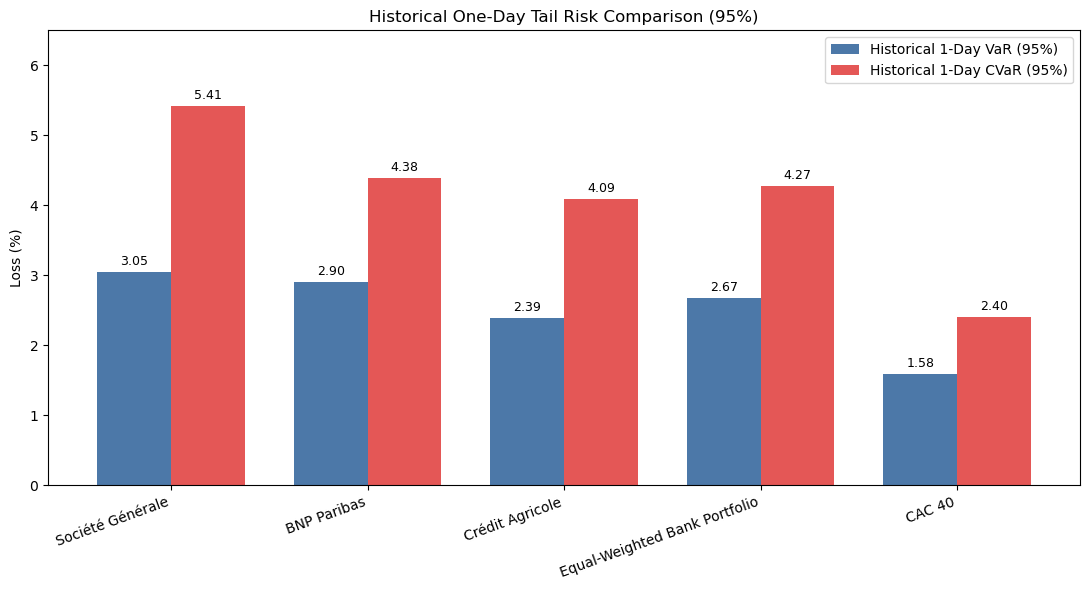

Saved: /Users/faraz/french-bank-portfolio-risk/figures/var_cvar_comparison.png


In [17]:
ax = tail_risk_summary.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#4C78A8", "#E45756"],
    width=0.75
)

ax.set_title("Historical One-Day Tail Risk Comparison (95%)")
ax.set_xlabel("")
ax.set_ylabel("Loss (%)")
ax.legend(title="")
ax.set_ylim(0, tail_risk_summary.to_numpy().max() * 1.20)

plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

figure_path = FIGURES_DIR / "var_cvar_comparison.png"

plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {figure_path}")

## Drawdown Analysis

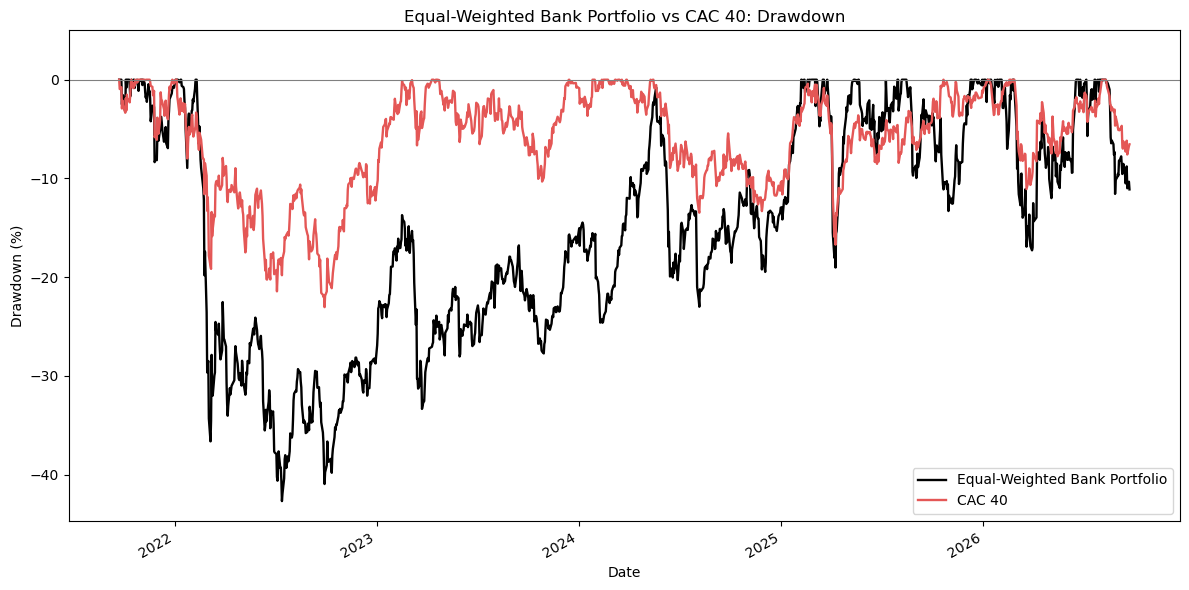

Saved: /Users/faraz/french-bank-portfolio-risk/figures/drawdown.png


In [18]:
# Compare portfolio drawdown with the CAC 40
drawdown_pct = drawdown[
    ["Equal-Weighted Bank Portfolio", BENCHMARK_NAME]
].mul(100)

ax = drawdown_pct.plot(
    figsize=(12, 6),
    linewidth=1.7,
    color=["black", "#E45756"]
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Equal-Weighted Bank Portfolio vs CAC 40: Drawdown")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")
ax.set_ylim(drawdown_pct.min().min() - 2, 5)
ax.legend(title="")

figure_path = FIGURES_DIR / "drawdown.png"

plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {figure_path}")

## 60-Day Rolling Volatility

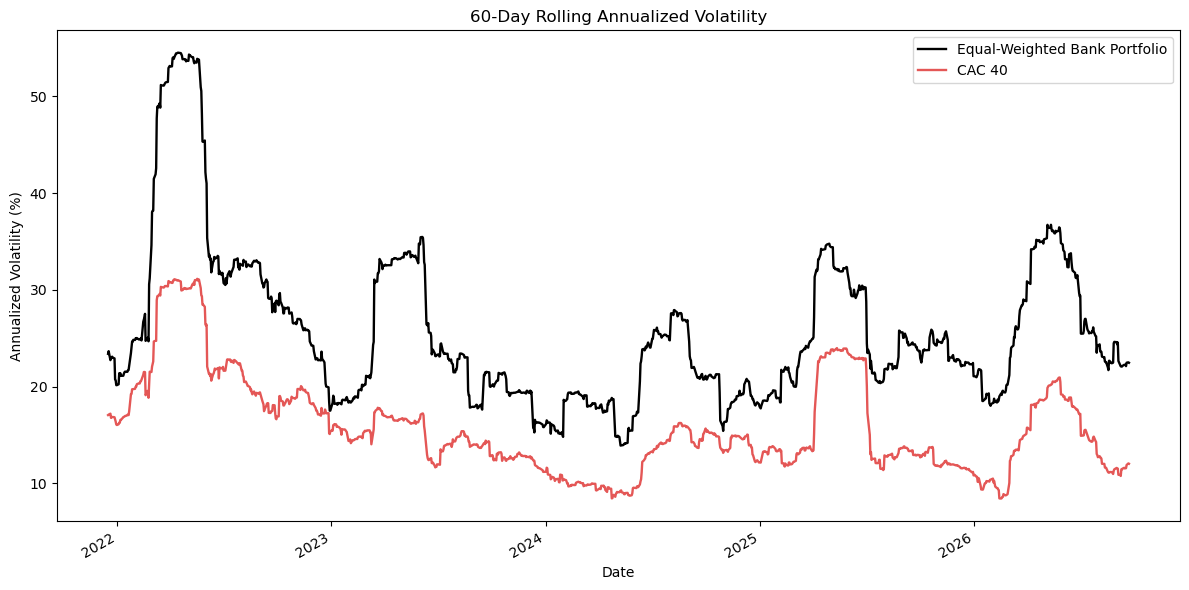

Saved: /Users/faraz/french-bank-portfolio-risk/figures/rolling_volatility.png


In [19]:
ROLLING_WINDOW = 60

# Annualized volatility over the previous 60 trading days
rolling_volatility = (
    analysis_returns[
        ["Equal-Weighted Bank Portfolio", BENCHMARK_NAME]
    ]
    .rolling(window=ROLLING_WINDOW)
    .std()
    .mul(np.sqrt(TRADING_DAYS))
    .mul(100)
)

ax = rolling_volatility.plot(
    figsize=(12, 6),
    linewidth=1.7,
    color=["black", "#E45756"]
)

ax.set_title("60-Day Rolling Annualized Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Volatility (%)")
ax.legend(title="")

figure_path = FIGURES_DIR / "rolling_volatility.png"

plt.tight_layout()
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {figure_path}")

## Key Findings

- The equal-weighted bank portfolio generated a total price return of 106.64% and a CAGR of 15.63%, exceeding the CAC 40's total price return of 21.68% and CAGR of 4.01%.
- Portfolio annualized volatility was 26.70%, above the CAC 40's 16.32%, and its beta of 1.20 indicates above-market sensitivity.
- Diversification reduced volatility relative to Société Générale and BNP Paribas, but not relative to Crédit Agricole.
- The portfolio's Sharpe ratio of 0.67 exceeded those of BNP Paribas, Crédit Agricole, and the CAC 40, but remained below Société Générale's 0.76.
- The portfolio experienced a maximum drawdown of -42.69%, materially deeper than the CAC 40's -23.04%, showing that diversification within one banking sector offered limited downside protection.
- Historical one-day 95% VaR and CVaR for the portfolio were 2.67% and 4.27%, respectively. These were lower than Société Générale and BNP Paribas, but higher than Crédit Agricole and the CAC 40.

## Limitations

- The analysis uses closing prices, so it measures price returns rather than total returns including dividends.
- The portfolio is assumed to be rebalanced daily, without transaction costs, taxes, or liquidity constraints.
- All portfolio holdings are French banks; therefore, diversification is limited by sector concentration.
- Historical VaR and CVaR describe past return behaviour and do not predict future losses.
- Market data may be revised by the data provider.
- This project is for educational purposes only and is not investment advice.

## Reproducible Outputs

In [20]:
# Combine all calculated metrics into one reproducible output table
final_summary = summary.join(tail_risk_summary)

metrics_path = DATA_DIR / "portfolio_metrics.csv"

final_summary.to_csv(
    metrics_path,
    index_label="Asset",
    float_format="%.4f"
)

print(f"Saved: {metrics_path}")

final_summary.round(2)

Saved: /Users/faraz/french-bank-portfolio-risk/data/processed/portfolio_metrics.csv


,Total Price Return (%),CAGR (%),Annualized Volatility (%),Sharpe Ratio (rf = 0%),Maximum Drawdown (%),Beta vs CAC 40,Historical 1-Day VaR (95%),Historical 1-Day CVaR (95%)
Société Générale,177.17,22.63,34.43,0.76,-47.86,1.38,3.05,5.41
BNP Paribas,86.35,13.27,28.42,0.57,-38.61,1.25,2.90,4.38
Crédit Agricole,52.59,8.82,24.18,0.47,-42.40,0.97,2.39,4.09
Equal-Weighted Bank Portfolio,106.64,15.63,26.70,0.67,-42.69,1.20,2.67,4.27
CAC 40,21.68,4.01,16.32,0.32,-23.04,1.00,1.58,2.40


In [21]:
expected_files = [
    FIGURES_DIR / "indexed_performance.png",
    FIGURES_DIR / "correlation_matrix.png",
    FIGURES_DIR / "var_cvar_comparison.png",
    FIGURES_DIR / "drawdown.png",
    FIGURES_DIR / "rolling_volatility.png",
    DATA_DIR / "portfolio_metrics.csv",
]

for file_path in expected_files:
    status = "✓" if file_path.exists() else "✗"
    print(f"{status} {file_path.relative_to(PROJECT_DIR)}")

✓ figures/indexed_performance.png
✓ figures/correlation_matrix.png
✓ figures/var_cvar_comparison.png
✓ figures/drawdown.png
✓ figures/rolling_volatility.png
✓ data/processed/portfolio_metrics.csv


In [22]:
requirements_text = """yfinance
pandas
numpy
matplotlib
seaborn
"""

gitignore_text = """.ipynb_checkpoints/
__pycache__/
*.pyc
.DS_Store
.env
"""

requirements_path = PROJECT_DIR / "requirements.txt"
gitignore_path = PROJECT_DIR / ".gitignore"

requirements_path.write_text(requirements_text, encoding="utf-8")
gitignore_path.write_text(gitignore_text, encoding="utf-8")

print(f"Saved: {requirements_path}")
print(f"Saved: {gitignore_path}")

Saved: /Users/faraz/french-bank-portfolio-risk/requirements.txt
Saved: /Users/faraz/french-bank-portfolio-risk/.gitignore


In [23]:
%%writefile /Users/faraz/french-bank-portfolio-risk/README.md
# French Bank Portfolio: Diversification and Market Risk Analysis

## Overview

This project evaluates whether an equal-weighted portfolio of three listed French banks offered improved risk-adjusted price performance relative to its individual holdings and the CAC 40 benchmark.

## Research Question

Does an equal-weighted portfolio of Société Générale, BNP Paribas, and Crédit Agricole improve risk-adjusted price performance relative to its individual constituents and the CAC 40?

## Data

- **Source:** Yahoo Finance, accessed with `yfinance`
- **Frequency:** Daily closing prices
- **Analysis period:** 23 September 2021 to 22 September 2026
- **Aligned observations:** 1,280
- **Assets:** Société Générale (`GLE.PA`), BNP Paribas (`BNP.PA`), Crédit Agricole (`ACA.PA`), and CAC 40 (`^FCHI`)

## Portfolio Construction

The portfolio assigns an equal weight of one-third to each bank and is rebalanced daily.

## Methodology

The analysis calculates total price return, CAGR, annualized volatility, Sharpe ratio with a 0% risk-free rate, maximum drawdown, beta relative to the CAC 40, historical one-day 95% VaR and CVaR, correlations, and 60-day rolling volatility.

## Results

| Asset | Total Price Return | CAGR | Annualized Volatility | Sharpe Ratio | Maximum Drawdown | Beta vs CAC 40 |
|---|---:|---:|---:|---:|---:|---:|
| Société Générale | 177.17% | 22.63% | 34.43% | 0.76 | -47.86% | 1.38 |
| BNP Paribas | 86.35% | 13.27% | 28.42% | 0.57 | -38.61% | 1.25 |
| Crédit Agricole | 52.59% | 8.82% | 24.18% | 0.47 | -42.40% | 0.97 |
| Equal-Weighted Bank Portfolio | 106.64% | 15.63% | 26.70% | 0.67 | -42.69% | 1.20 |
| CAC 40 | 21.68% | 4.01% | 16.32% | 0.32 | -23.04% | 1.00 |

### Historical One-Day Tail Risk (95%)

| Asset | VaR | CVaR |
|---|---:|---:|
| Société Générale | 3.05% | 5.41% |
| BNP Paribas | 2.90% | 4.38% |
| Crédit Agricole | 2.39% | 4.09% |
| Equal-Weighted Bank Portfolio | 2.67% | 4.27% |
| CAC 40 | 1.58% | 2.40% |

## Key Findings

- The equal-weighted bank portfolio outperformed the CAC 40 in total price return and CAGR.
- Portfolio volatility was lower than that of Société Générale and BNP Paribas, but higher than that of Crédit Agricole and the CAC 40.
- The portfolio's Sharpe ratio exceeded those of BNP Paribas, Crédit Agricole, and the CAC 40, but remained below Société Générale's.
- The portfolio's beta of 1.20 indicates above-market sensitivity relative to the CAC 40.
- The portfolio experienced a maximum drawdown of -42.69%, compared with -23.04% for the CAC 40.
- High positive correlations among the three banks limited the downside protection offered by diversification.

## Visualizations

### Indexed Price Performance

![Indexed price performance](figures/indexed_performance.png)

### Daily Return Correlation Matrix

![Correlation matrix](figures/correlation_matrix.png)

### Historical VaR and CVaR Comparison

![VaR and CVaR comparison](figures/var_cvar_comparison.png)

### Drawdown Comparison

![Drawdown comparison](figures/drawdown.png)

### 60-Day Rolling Volatility

![Rolling volatility](figures/rolling_volatility.png)

## Reproducibility

Install packages with `pip install -r requirements.txt`, then run `jupyter notebook french-bank-portfolio-risk.ipynb`.

## Limitations

- The analysis uses closing prices, so dividends are not included.
- Daily rebalancing is assumed without transaction costs, taxes, or liquidity constraints.
- The portfolio is concentrated in one sector, so diversification is limited.
- Historical VaR and CVaR describe past behaviour and do not predict future losses.
- This project is for educational purposes only and is not investment advice.

## Skills Demonstrated

- Python and Jupyter Notebook
- Financial data collection with `yfinance`
- Data cleaning and alignment with `pandas`
- Portfolio construction and risk measurement
- Correlation, beta, drawdown, VaR, and CVaR analysis
- Financial data visualization with `matplotlib` and `seaborn`
- Reproducible project organization

Overwriting /Users/faraz/french-bank-portfolio-risk/README.md
